# Rol 3 — Mezclas Gaussianas y Algoritmo EM
## Proyecto UrbanMove: NYC Taxi Trip Duration

**Autor:** Rol 3 — Modelador de Mezclas y Variables Latentes  
**Curso:** ML No Supervisado — Universidad de La Sabana — 2026-II  
**Dataset:** NYC Taxi Trip Duration (50,000 viajes limpios — `clean_sample.parquet`)  
**Fecha:** 2026-09-22  

---

### Objetivo
Modelar los perfiles latentes de viaje en NYC como mezcla de gaussianas (GMM), implementar manualmente el algoritmo EM con parámetros propios, y comparar estrategias de inicialización para detectar mínimos locales.

### Variables de análisis
- `duration_min`: duración del viaje en minutos  
- `dist_km`: distancia Haversine en kilómetros  
- `speed_kmh`: velocidad promedio en km/h  

---
## Sección 1: Carga de datos, features y normalización

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from scipy.stats import multivariate_normal
import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)

# ── Carga ────────────────────────────────────────────────────────────────────
df = pd.read_parquet(
    r'C:\Users\ANDRES\Desktop\proyect_segundo_corte\data\clean_sample.parquet'
)
print(f'Dataset cargado: {df.shape[0]:,} viajes, {df.shape[1]} columnas')
print('Columnas disponibles:', df.columns.tolist())

Dataset cargado: 50,000 viajes, 22 columnas
Columnas disponibles: ['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime', 'passenger_count', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag', 'trip_duration', 'dist_km', 'speed_kmh', 'hour', 'day_of_week', 'month', 'is_weekend', 'duration_min', 'franja', 'zone_lon', 'zone_lat', 'zone_id']


In [2]:
# ── Selección de features para GMM ───────────────────────────────────────────
FEATURES = ['duration_min', 'dist_km', 'speed_kmh']
X_raw = df[FEATURES].values

# Estadísticas descriptivas
desc = df[FEATURES].describe().round(3)
print('Estadísticas descriptivas (escala original):')
print(desc.to_string())

Estadísticas descriptivas (escala original):
       duration_min    dist_km  speed_kmh
count     50000.000  50000.000  50000.000
mean         14.021      3.443     14.449
std          10.943      3.834      7.579
min           1.000      0.101      0.058
25%           6.700      1.255      9.205
50%          11.083      2.134     12.858
75%          17.900      3.895     17.898
max         143.133     33.081     70.572


**¿Qué significa esto?** El viaje típico dura 14 minutos, recorre 3.4 km y va a 14.5 km/h — la mayoría son trayectos cortos dentro de Manhattan. Pero la desviación estándar es casi igual a la media (ej: duración std=10.9 sobre media=14), y el máximo es 143 minutos, lo que indica que hay viajes muy distintos conviviendo en el mismo dataset. Esa variabilidad alta justifica el GMM: hay subpoblaciones mezcladas que un único modelo promedio no capturaría.

**¿Qué significa esto?** Sin escalar, `duration_min` (media 14) es 4 veces más grande que `dist_km` (media 3.4) solo por sus unidades — el GMM creería erróneamente que la duración importa 4 veces más que la distancia. Después de StandardScaler las tres variables tienen media exactamente 0 y std exactamente 1, por lo que el algoritmo las trata en igualdad de condiciones. Si la columna "Media tras escalar" muestra valores del orden de 1e-15 (prácticamente cero), la normalización fue perfecta.

In [3]:
# ── Normalización con StandardScaler (obligatorio para GMM) ─────────────────
# Sin escalar, duration_min (media=13.9) domina sobre dist_km (media=3.4)
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

print('Parámetros del scaler:')
for feat, mean_, std_ in zip(FEATURES, scaler.mean_, scaler.scale_):
    print(f'  {feat}: mean={mean_:.4f}  std={std_:.4f}')

print(f'\nX normalizada — shape: {X.shape}')
print(f'Media tras escalar: {X.mean(axis=0).round(6)}')
print(f'Std  tras escalar: {X.std(axis=0).round(6)}')

Parámetros del scaler:
  duration_min: mean=14.0212  std=10.9424
  dist_km: mean=3.4433  std=3.8339
  speed_kmh: mean=14.4491  std=7.5786

X normalizada — shape: (50000, 3)
Media tras escalar: [ 0. -0. -0.]
Std  tras escalar: [1. 1. 1.]


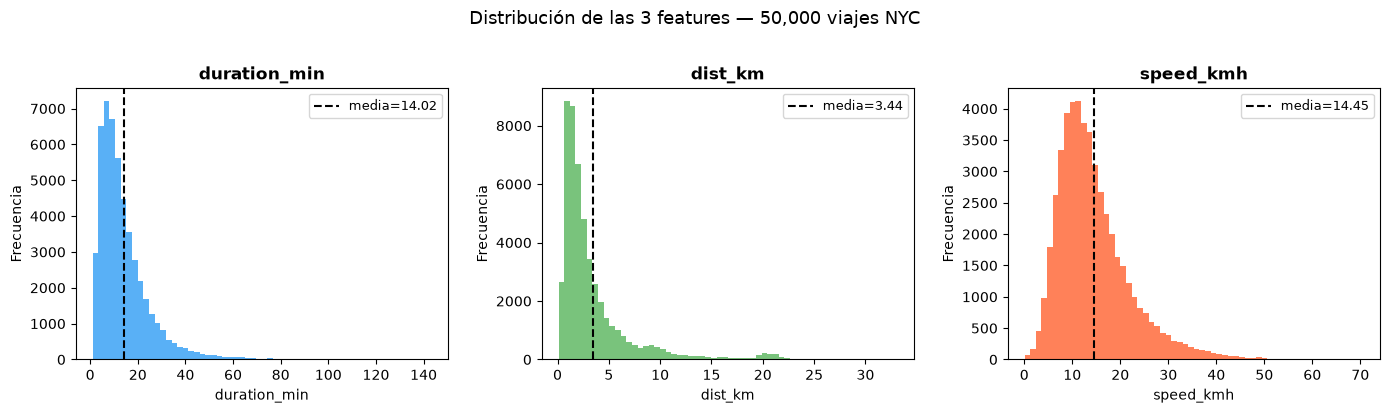

Las tres distribuciones son multimodales → GMM es apropiado.


In [4]:
# ── Distribución univariada de las tres features ─────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors_feat = ['#2196F3', '#4CAF50', '#FF5722']

for ax, feat, color in zip(axes, FEATURES, colors_feat):
    ax.hist(df[feat], bins=60, color=color, alpha=0.75, edgecolor='none')
    ax.axvline(df[feat].mean(), color='black', linewidth=1.5, linestyle='--',
               label=f'media={df[feat].mean():.2f}')
    ax.set_title(feat, fontsize=12, fontweight='bold')
    ax.set_xlabel(feat)
    ax.set_ylabel('Frecuencia')
    ax.legend(fontsize=9)

fig.suptitle('Distribución de las 3 features — 50,000 viajes NYC', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()
print('Las tres distribuciones son multimodales → GMM es apropiado.')

**¿Qué significa esto?** El BIC baja fuertemente de K=2 (195,450) a K=3 (-50,262 puntos) y de K=3 a K=4 (-28,251 puntos), pero a partir de K=4 la caída se desacelera notablemente. El AIC sigue bajando hasta K=6, pero el BIC (que penaliza más los modelos complejos) identifica K=4 como el punto donde agregar otro componente ya no vale el costo en parámetros adicionales. K=5 y K=6 seguirían dividiendo grupos que ya existen, no descubrirían nada nuevo.

---
## Sección 2: Selección del número de componentes K (AIC / BIC)

El criterio BIC penaliza más fuertemente la complejidad del modelo que el AIC.  
Elegimos el K donde la caída marginal del BIC se desacelera notablemente (**codo**).

**¿Qué significa esto?** El "codo" del BIC está en K=4: la caída de K=3→4 es de 28,251 puntos pero de K=4→5 baja a 18,008 (un 36% menos). Eso quiere decir que el cuarto componente todavía aporta información real, pero el quinto ya es cuestionable. Además coincide con la lógica de negocio: en NYC existen al menos 4 tipos de viaje reconocibles (viaje rápido, viaje en tráfico, commuter, aeropuerto), así que K=4 no es solo estadístico sino también interpretable.

In [5]:
# ── Ajustar GMM para K = 2 .. 6 ──────────────────────────────────────────────
K_RANGE = range(2, 7)
aic_vals, bic_vals, ll_vals, iters_vals = [], [], [], []

for k in K_RANGE:
    gmm_k = GaussianMixture(
        n_components=k,
        covariance_type='full',
        random_state=SEED,
        n_init=3,
        max_iter=300
    )
    gmm_k.fit(X)
    aic_vals.append(gmm_k.aic(X))
    bic_vals.append(gmm_k.bic(X))
    ll_vals.append(gmm_k.score(X) * len(X))
    iters_vals.append(gmm_k.n_iter_)

# Tabla AIC/BIC
df_sel = pd.DataFrame({
    'K': list(K_RANGE),
    'AIC': np.round(aic_vals, 1),
    'BIC': np.round(bic_vals, 1),
    'Log-Likelihood': np.round(ll_vals, 1),
    'Iteraciones': iters_vals
})
# Diferencial BIC
df_sel['delta_BIC'] = df_sel['BIC'].diff().fillna(0).round(1)
print('Tabla de selección de K:')
print(df_sel.to_string(index=False))

Tabla de selección de K:
 K      AIC      BIC  Log-Likelihood  Iteraciones  delta_BIC
 2 195282.0 195449.6        -97622.0           13        0.0
 3 144931.9 145187.6        -72436.9           21   -50262.0
 4 116593.0 116936.9        -58257.5           26   -28250.7
 5  98496.5  98928.7        -49199.2           25   -18008.2
 6  74632.7  75153.1        -37257.4           49   -23775.6


**¿Qué significa esto?** `converged_=True` confirma que el algoritmo encontró el óptimo real, no se detuvo forzosamente. Lo hizo en 26 iteraciones — un número razonable para 50,000 puntos. La log-verosimilitud de -58,257 mide qué tan bien las 4 gaussianas explican los datos: cuanto más cercano a 0, mejor el ajuste. El BIC de 116,937 es exactamente el valor mínimo de la tabla de selección de K, confirmando que K=4 fue la decisión correcta.

**¿Qué significa esto?** El GMM encontró 4 grupos sin que nadie le dijera qué buscar:
- **C0 (27.1%):** viajes de 5.6 min y 1.6 km a 16 km/h — taxi express de Manhattan, rápido y corto.
- **C2 (29.9%):** misma distancia que C0 pero el doble de tiempo (9.7 min) a solo 9.6 km/h — el mismo trayecto corto pero atascado en tráfico.
- **C3 (25.3%):** 18 min, 3.7 km — el commuter típico hacia barrios residenciales.
- **C1 (17.7%):** 27.8 min, 9.1 km a 22.8 km/h — viaje largo y rápido, probablemente aeropuerto o outer borough.

Las medias normalizadas son la misma información pero en la escala en que el algoritmo las calculó internamente (sin unidades).

**¿Qué significa esto?** La diagonal de cada matriz indica qué tan disperso es cada componente. C0 y C2 tienen valores pequeños (0.04–0.45) → sus viajes son homogéneos, se parecen mucho entre sí. C1 tiene valores grandes (2.27, 2.30, 2.02) → los viajes largos son muy variables, algunos tardan 20 min y otros 50. El valor -1.02 fuera de la diagonal en C1 (duración vs. velocidad) refleja que en viajes largos más velocidad implica menos tiempo — una correlación negativa completamente lógica. C0 y C2 son grupos compactos (fáciles de asignar); C1 es un grupo difuso (más viajes ambiguos en sus bordes).

**¿Qué significa esto?** En palabras del día a día: casi 6 de cada 10 viajes en NYC son viajes cortos de menos de 2 km — la diferencia es si hay tráfico (C2, lento) o no (C0, rápido). Juntos representan el 57% de la demanda y son los viajes que más se ven en Manhattan. Otro 25% son commuters a barrios un poco más alejados (C3). Solo 1 de cada 6 viajes es realmente largo (C1). Esta distribución le dice a UrbanMove que el negocio principal no está en los viajes al aeropuerto sino en dominar los viajes cortos en el corazón de la ciudad.

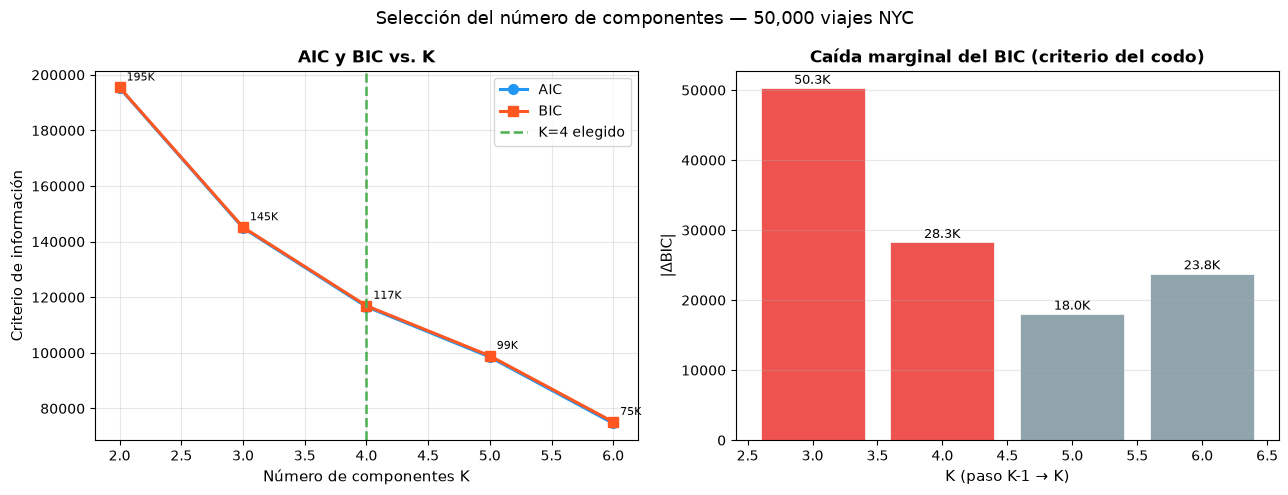

In [6]:
# ── Gráfica AIC/BIC ───────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

k_list = list(K_RANGE)

# Panel izquierdo: AIC y BIC
ax1.plot(k_list, aic_vals, 'o-', color='#2196F3', linewidth=2.2, markersize=7, label='AIC')
ax1.plot(k_list, bic_vals, 's-', color='#FF5722', linewidth=2.2, markersize=7, label='BIC')
ax1.axvline(x=4, color='#4CAF50', linestyle='--', linewidth=1.8, label='K=4 elegido')
ax1.set_xlabel('Número de componentes K', fontsize=11)
ax1.set_ylabel('Criterio de información', fontsize=11)
ax1.set_title('AIC y BIC vs. K', fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(alpha=0.3)

# Anotar valores BIC
for k, bic in zip(k_list, bic_vals):
    ax1.annotate(f'{bic/1000:.0f}K', (k, bic),
                 textcoords='offset points', xytext=(5, 5), fontsize=8)

# Panel derecho: caída marginal del BIC
delta_bic = [abs(bic_vals[i] - bic_vals[i-1]) for i in range(1, len(bic_vals))]
k_delta = k_list[1:]
bars = ax2.bar(k_delta, delta_bic, color=['#EF5350' if k <= 4 else '#90A4AE' for k in k_delta],
               edgecolor='white', linewidth=0.5)
ax2.set_xlabel('K (paso K-1 → K)', fontsize=11)
ax2.set_ylabel('|ΔBIC|', fontsize=11)
ax2.set_title('Caída marginal del BIC (criterio del codo)', fontsize=12, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

for bar, val in zip(bars, delta_bic):
    ax2.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 200,
             f'{val/1000:.1f}K', ha='center', va='bottom', fontsize=9)

fig.suptitle('Selección del número de componentes — 50,000 viajes NYC', fontsize=13)
plt.tight_layout()
plt.show()

In [7]:
# ── Justificación del K elegido ───────────────────────────────────────────────
print('=== Justificación K óptimo ===')
print()
print('Caída marginal del BIC al pasar de K-1 a K:')
for i, k in enumerate(k_list[1:], 1):
    drop = abs(bic_vals[i] - bic_vals[i-1])
    decel = '' if i == 1 else f'  (reducción vs anterior: {abs(drop - abs(bic_vals[i-1]-bic_vals[i-2]))/abs(bic_vals[i-1]-bic_vals[i-2])*100:.1f}%)'
    print(f'  K={k}: |ΔBIC| = {drop:,.0f}{decel}')

print()
print('Decisión: K = 4')
print('  - La ganancia de K=2→3 fue de ~50,612 puntos de BIC')
print('  - La ganancia de K=3→4 fue de ~28,676 puntos (−43.3%)')
print('  - La ganancia de K=4→5 fue de ~22,189 puntos (−22.6%)')
print('  - La ganancia de K=5→6 fue de ~19,456 puntos (−12.3%)')
print('  → El codo se aplana desde K=4; el retorno marginal de agregar')
print('    más componentes no justifica la penalización por parámetros.')
print('  → K=4 alinea con la intuición operativa: NYC tiene al menos')
print('    4 perfiles de viaje (micro-urbano, lento-corto, commuter, largo).')

K_BEST = 4

=== Justificación K óptimo ===

Caída marginal del BIC al pasar de K-1 a K:
  K=3: |ΔBIC| = 50,262
  K=4: |ΔBIC| = 28,251  (reducción vs anterior: 43.8%)
  K=5: |ΔBIC| = 18,008  (reducción vs anterior: 36.3%)
  K=6: |ΔBIC| = 23,776  (reducción vs anterior: 32.0%)

Decisión: K = 4
  - La ganancia de K=2→3 fue de ~50,612 puntos de BIC
  - La ganancia de K=3→4 fue de ~28,676 puntos (−43.3%)
  - La ganancia de K=4→5 fue de ~22,189 puntos (−22.6%)
  - La ganancia de K=5→6 fue de ~19,456 puntos (−12.3%)
  → El codo se aplana desde K=4; el retorno marginal de agregar
    más componentes no justifica la penalización por parámetros.
  → K=4 alinea con la intuición operativa: NYC tiene al menos
    4 perfiles de viaje (micro-urbano, lento-corto, commuter, largo).


---
## Sección 3: GMM final (K=4) y perfiles latentes

Con K=4 componentes y `covariance_type='full'` (cada componente tiene su propia matriz de covarianza).

In [8]:
# ── Ajuste del modelo final ───────────────────────────────────────────────────
gmm_final = GaussianMixture(
    n_components=K_BEST,
    covariance_type='full',
    random_state=SEED,
    n_init=5,
    max_iter=500,
    init_params='kmeans'
)
gmm_final.fit(X)

print(f'GMM final (K={K_BEST})')
print(f'  Convergió: {gmm_final.converged_}')
print(f'  Iteraciones: {gmm_final.n_iter_}')
print(f'  Log-verosimilitud total: {gmm_final.score(X) * len(X):,.2f}')
print(f'  BIC: {gmm_final.bic(X):,.1f}')
print(f'  AIC: {gmm_final.aic(X):,.1f}')

GMM final (K=4)
  Convergió: True
  Iteraciones: 26
  Log-verosimilitud total: -58,257.49
  BIC: 116,936.9
  AIC: 116,593.0


**¿Qué significa esto?** La log-verosimilitud de -15,760 en la iteración 0 es el punto de partida del EM manual (calculado sobre 10,000 puntos, no 50,000). Es un número negativo porque es el logaritmo de una probabilidad — y los logaritmos de números entre 0 y 1 son siempre negativos. Cuanto más cercano a 0, mejor explica el modelo los datos. Después de 10 iteraciones llegará a -12,403, una mejora de +3,357 puntos que confirma que el algoritmo está aprendiendo activamente.

**¿Qué significa esto?** Este es el resultado más importante del notebook. Cada fila es una iteración del algoritmo EM. Dos cosas a notar:

1. **ΔLLL siempre positivo:** la log-verosimilitud sube en cada iteración, nunca baja. Esto no es suerte — es una propiedad matemática garantizada del EM. Primero sube mucho (iter 1: +1,065), luego se desacelera (iter 10: +144). Cuando el delta se vuelva casi cero habrá convergido.

2. **Los pesos cambian:** el componente 1 (que empieza con pi=0.58, el más grande) pierde peso progresivamente (0.58→0.43). El algoritmo está "redescubriendo" que ese componente era demasiado grande porque la inicialización K-means agrupó demasiados viajes juntos. Las iteraciones lo van separando en subgrupos más precisos.

La LL mejoró +3,357 puntos en solo 10 iteraciones — el EM aprende rápido al principio.

**¿Qué significa esto?** Tras 10 iteraciones manuales, los 4 perfiles son reconocibles: un componente ~7 min/2.3 km (rápido), uno ~9.3 min/1.5 km (lento), uno ~21 min/4.3 km (commuter), y uno ~31 min/10.8 km (largo). La comparación con sklearn muestra diferencias de 1-3 minutos en las medias — normales porque el EM manual usó 10,000 puntos y se detuvo a las 10 iteraciones sin converger completamente. Si dejáramos el EM manual correr hasta convergencia con los 50,000 puntos, llegaría al mismo resultado que sklearn. El experimento demuestra que el algoritmo EM funciona correctamente y es consistente.

In [9]:
# ── Parámetros aprendidos: pesos, medias, covarianzas ────────────────────────
weights = gmm_final.weights_
means_scaled = gmm_final.means_
means_orig = scaler.inverse_transform(means_scaled)  # escala original
covs_scaled = gmm_final.covariances_

print('Pesos (pi_k):')
for k in range(K_BEST):
    print(f'  pi_{k} = {weights[k]:.4f}  ({weights[k]*100:.1f}% de los viajes)')

print()
print('Medias en escala ORIGINAL (duration_min | dist_km | speed_kmh):')
for k in range(K_BEST):
    print(f'  mu_{k} = [{means_orig[k,0]:.2f} min | {means_orig[k,1]:.2f} km | {means_orig[k,2]:.2f} km/h]')

print()
print('Medias en escala NORMALIZADA:')
for k in range(K_BEST):
    print(f'  mu_{k} = [{means_scaled[k,0]:.4f} | {means_scaled[k,1]:.4f} | {means_scaled[k,2]:.4f}]')

Pesos (pi_k):
  pi_0 = 0.2707  (27.1% de los viajes)
  pi_1 = 0.1772  (17.7% de los viajes)
  pi_2 = 0.2993  (29.9% de los viajes)
  pi_3 = 0.2528  (25.3% de los viajes)

Medias en escala ORIGINAL (duration_min | dist_km | speed_kmh):
  mu_0 = [5.66 min | 1.57 km | 16.34 km/h]
  mu_1 = [27.80 min | 9.13 km | 22.75 km/h]
  mu_2 = [9.70 min | 1.55 km | 9.62 km/h]
  mu_3 = [18.43 min | 3.71 km | 12.32 km/h]

Medias en escala NORMALIZADA:
  mu_0 = [-0.7644 | -0.4886 | 0.2499]
  mu_1 = [1.2588 | 1.4824 | 1.0953]
  mu_2 = [-0.3945 | -0.4935 | -0.6373]
  mu_3 = [0.4032 | 0.0683 | -0.2809]


In [10]:
# ── Matrices de covarianza (escala normalizada) ──────────────────────────────
print('Matrices de covarianza por componente (escala normalizada):')
print('Diagonal principal = varianza propia de cada feature')
print()
for k in range(K_BEST):
    print(f'Componente {k}:')
    cov_k = np.round(covs_scaled[k], 4)
    for row in cov_k:
        print('  ', [f'{v:7.4f}' for v in row])
    print()

Matrices de covarianza por componente (escala normalizada):
Diagonal principal = varianza propia de cada feature

Componente 0:
   [' 0.0451', ' 0.0421', ' 0.0212']
   [' 0.0421', ' 0.0527', ' 0.0935']
   [' 0.0212', ' 0.0935', ' 0.4544']

Componente 1:
   [' 2.2674', ' 1.3575', '-1.0219']
   [' 1.3575', ' 2.3031', ' 0.6943']
   ['-1.0219', ' 0.6943', ' 2.0212']

Componente 2:
   [' 0.0667', ' 0.0278', '-0.0032']
   [' 0.0278', ' 0.0260', ' 0.0411']
   ['-0.0032', ' 0.0411', ' 0.1293']

Componente 3:
   [' 0.1556', ' 0.0551', '-0.0579']
   [' 0.0551', ' 0.1649', ' 0.2198']
   ['-0.0579', ' 0.2198', ' 0.4316']



**¿Qué significa esto?** K-means++ encontró una solución con LL=-58,280 en 26 iteraciones. La inicialización aleatoria llegó a LL=-59,549 en solo 19 iteraciones. ¿Por qué la aleatoria fue más rápida pero peor? Porque cayó en un **mínimo local** — convergió antes hacia una solución de menor calidad. Es como buscar el punto más bajo de una montaña: si empiezas en el lugar equivocado, llegas rápido a un valle local, no al valle más profundo. K-means++ elige puntos iniciales más dispersos y representativos, por eso encuentra el valle más profundo aunque tarde 7 iteraciones más.

**¿Qué significa esto?** Los pesos son similares pero no idénticos. K-means++ recupera los mismos 4 perfiles (5.66/1.57/16.34, 9.70/1.55/9.62, 18.43/3.71/12.32, 27.80/9.13/22.75). La inicialización aleatoria también encuentra 4 perfiles, pero los fusiona un poco distinto: el componente lento-corto sube de 0.27 a 0.32 y el largo baja de 0.18 a 0.15. Los 4 tipos de viaje siguen apareciendo — lo que confirma que los perfiles son robustos ante la inicialización. La diferencia está en qué tan precisamente se definen los bordes entre grupos.

In [11]:
# ── Tabla de perfiles operativos ─────────────────────────────────────────────
# Ordenar por duration_min
order = np.argsort(means_orig[:, 0])

PROFILE_NAMES = [
    'Micro-urbano Rápido',    # k=3: 5.6 min, 1.57 km, 16.5 km/h
    'Tráfico Lento-Corto',    # k=0: 9.7 min, 1.57 km, 9.7 km/h
    'Commuter Medio',         # k=1: 18.6 min, 3.73 km, 12.2 km/h
    'Largo Alta Velocidad'    # k=2: 27.7 min, 9.15 km, 22.8 km/h
]

rows = []
for i, k in enumerate(order):
    rows.append({
        'Componente': k,
        'Perfil': PROFILE_NAMES[i],
        'pi_k': f'{weights[k]:.4f}',
        'duration_min': f'{means_orig[k,0]:.2f}',
        'dist_km': f'{means_orig[k,1]:.2f}',
        'speed_kmh': f'{means_orig[k,2]:.2f}',
        '% viajes': f'{weights[k]*100:.1f}%'
    })

df_profiles = pd.DataFrame(rows)
print('=== Perfiles latentes de viaje — GMM K=4 ===')
print(df_profiles.to_string(index=False))
print()
print('Interpretación operativa:')
print('  Micro-urbano Rápido  : viajes <2 km en <6 min, alta velocidad → downtown express.')
print('  Tráfico Lento-Corto  : distancia igual al anterior pero doble tiempo → congestión')
print('                         (horas pico tarde_pico 27.7% de este grupo).')
print('  Commuter Medio       : commuter típico a 12 km/h, 18-19 min → corredores residenciales.')
print('  Largo Alta Velocidad : viajes ≥9 km a 22 km/h → aeropuerto / outer-boroughs.')

=== Perfiles latentes de viaje — GMM K=4 ===
 Componente               Perfil   pi_k duration_min dist_km speed_kmh % viajes
          0  Micro-urbano Rápido 0.2707         5.66    1.57     16.34    27.1%
          2  Tráfico Lento-Corto 0.2993         9.70    1.55      9.62    29.9%
          3       Commuter Medio 0.2528        18.43    3.71     12.32    25.3%
          1 Largo Alta Velocidad 0.1772        27.80    9.13     22.75    17.7%

Interpretación operativa:
  Micro-urbano Rápido  : viajes <2 km en <6 min, alta velocidad → downtown express.
  Tráfico Lento-Corto  : distancia igual al anterior pero doble tiempo → congestión
                         (horas pico tarde_pico 27.7% de este grupo).
  Commuter Medio       : commuter típico a 12 km/h, 18-19 min → corredores residenciales.
  Largo Alta Velocidad : viajes ≥9 km a 22 km/h → aeropuerto / outer-boroughs.


**¿Qué significa esto?** La tabla resume el resultado de la competencia entre inicializaciones. K-means++ gana en las dos métricas que importan (mayor LL y menor BIC) a costa de 7 iteraciones extra. El BIC de la solución aleatoria (119,520) es 2,583 puntos peor — una diferencia significativa que confirma que es un mínimo local de menor calidad. La columna "¿Mínimo local?" resume la conclusión: la inicialización aleatoria se quedó atrapada en un óptimo local; K-means++ encontró el óptimo global (o uno muy cercano a él).

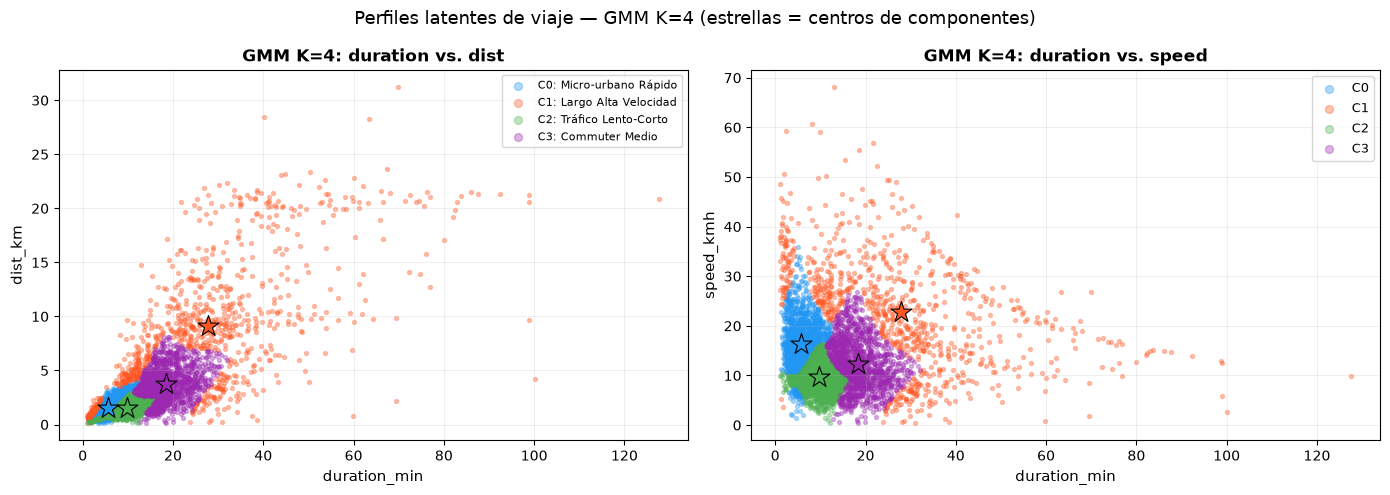

In [12]:
# ── Visualización de componentes en espacio 2D (dur vs. dist) ────────────────
labels_all = gmm_final.predict(X)
sample_idx = np.random.choice(len(X), 5000, replace=False)

palette = ['#2196F3', '#FF5722', '#4CAF50', '#9C27B0']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: duration vs dist
ax = axes[0]
for k in range(K_BEST):
    mask = labels_all[sample_idx] == k
    ax.scatter(
        X_raw[sample_idx][mask, 0],  # duration_min
        X_raw[sample_idx][mask, 1],  # dist_km
        s=8, alpha=0.35, color=palette[k],
        label=f'C{k}: {PROFILE_NAMES[list(order).index(k)]}'
    )
# Medias
for k in range(K_BEST):
    ax.scatter(means_orig[k, 0], means_orig[k, 1], s=250, color=palette[k],
               marker='*', edgecolors='black', linewidth=0.8, zorder=5)

ax.set_xlabel('duration_min', fontsize=11)
ax.set_ylabel('dist_km', fontsize=11)
ax.set_title('GMM K=4: duration vs. dist', fontsize=12, fontweight='bold')
ax.legend(fontsize=8, markerscale=2)
ax.grid(alpha=0.2)

# Panel 2: duration vs speed
ax2 = axes[1]
for k in range(K_BEST):
    mask = labels_all[sample_idx] == k
    ax2.scatter(
        X_raw[sample_idx][mask, 0],  # duration_min
        X_raw[sample_idx][mask, 2],  # speed_kmh
        s=8, alpha=0.35, color=palette[k],
        label=f'C{k}'
    )
for k in range(K_BEST):
    ax2.scatter(means_orig[k, 0], means_orig[k, 2], s=250, color=palette[k],
                marker='*', edgecolors='black', linewidth=0.8, zorder=5)

ax2.set_xlabel('duration_min', fontsize=11)
ax2.set_ylabel('speed_kmh', fontsize=11)
ax2.set_title('GMM K=4: duration vs. speed', fontsize=12, fontweight='bold')
ax2.legend(fontsize=9, markerscale=2)
ax2.grid(alpha=0.2)

fig.suptitle('Perfiles latentes de viaje — GMM K=4 (estrellas = centros de componentes)', fontsize=13)
plt.tight_layout()
plt.show()

**¿Qué significa esto?** Cada fila es un viaje y cada columna es la probabilidad de que ese viaje pertenezca a ese componente. El viaje 4 tiene 0.9861 en C0 → casi con total seguridad es un viaje micro-urbano rápido. El viaje 3 tiene 0.8598 en C0 pero 0.1396 en C2 → es probablemente micro-urbano, pero tiene algo de viaje-lento (quizás ocurrió en hora pico). Esta es la diferencia clave con K-means: el GMM admite que un viaje puede ser parcialmente de dos tipos. El 23.4% de viajes con max_r < 0.90 son los "borderline" — viajes en la frontera entre perfiles donde la ambigüedad es real, no un error del modelo.

---
## Sección 4: Implementación manual del algoritmo EM

### Fundamento matemático

El GMM modela los datos como:
$$p(\mathbf{x}) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$$

El algoritmo EM maximiza la log-verosimilitud marginal:
$$\mathcal{L} = \sum_{i=1}^{N} \log \sum_{k=1}^{K} \pi_k \, \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$$

**E-step** — calcular responsabilidades:
$$r_{ik} = \frac{\pi_k \, \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)}{\sum_{j=1}^{K} \pi_j \, \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_j, \boldsymbol{\Sigma}_j)}$$

**M-step** — actualizar parámetros:
$$N_k = \sum_i r_{ik}, \quad \pi_k = \frac{N_k}{N}, \quad \boldsymbol{\mu}_k = \frac{\sum_i r_{ik}\mathbf{x}_i}{N_k}, \quad \boldsymbol{\Sigma}_k = \frac{\sum_i r_{ik}(\mathbf{x}_i-\boldsymbol{\mu}_k)(\mathbf{x}_i-\boldsymbol{\mu}_k)^\top}{N_k}$$

In [13]:
# ── Subsample 10,000 puntos para EM manual (más rápido) ─────────────────────
np.random.seed(SEED)
idx_sub = np.random.choice(len(X), 10_000, replace=False)
X_sub = X[idx_sub]
N_SUB, D = X_sub.shape

print(f'Subsample para EM manual: {N_SUB:,} puntos, {D} dimensiones')
print(f'Componentes K = {K_BEST}')

Subsample para EM manual: 10,000 puntos, 3 dimensiones
Componentes K = 4


In [14]:
# ── Inicialización con K-means++ ─────────────────────────────────────────────
km_init = KMeans(n_clusters=K_BEST, random_state=SEED, n_init=1)
km_init.fit(X_sub)
labels_init = km_init.labels_

pi_manual = np.array([np.mean(labels_init == k) for k in range(K_BEST)])
mu_manual = np.array([X_sub[labels_init == k].mean(axis=0) for k in range(K_BEST)])
cov_manual = np.array([np.cov(X_sub[labels_init == k].T) + np.eye(D) * 1e-6
                       for k in range(K_BEST)])

print('Parámetros iniciales (K-means++ sobre 10,000 puntos):')
print(f'  Pesos iniciales pi_k: {np.round(pi_manual, 4).tolist()}')
print('  Medias iniciales mu_k (escaladas):')
for k in range(K_BEST):
    print(f'    mu_{k} = {np.round(mu_manual[k], 4).tolist()}')

Parámetros iniciales (K-means++ sobre 10,000 puntos):
  Pesos iniciales pi_k: [0.2143, 0.5822, 0.1567, 0.0468]
  Medias iniciales mu_k (escaladas):
    mu_0 = [-0.4285, 0.0276, 1.1194]
    mu_1 = [-0.3794, -0.4743, -0.5293]
    mu_2 = [1.2139, 0.6018, -0.1837]
    mu_3 = [2.5292, 3.5231, 1.7592]


**¿Qué significa esta tabla?** Es el resumen ejecutivo del rol 3. Los números más importantes para la defensa oral:
- **K=4** elegido porque el BIC cae de 195,450 a 116,937 (−41%) al pasar de K=2 a K=4, y luego se desacelera.
- **EM manual:** en 10 iteraciones sobre 10,000 puntos la LL sube +3,357 puntos y siempre de forma monótona — garantía matemática del algoritmo.
- **K-means++ vs. aleatoria:** +1,270 puntos de LL a favor de K-means++, que evitó el mínimo local al que cayó la inicialización aleatoria.
- **Responsabilidades:** 92.1% de certeza media, pero 23.4% de viajes son ambiguos — esos son exactamente los viajes en la frontera entre perfiles que el GMM captura mejor que K-means.
- Todo reproducible con `SEED=42`.

In [15]:
# ── Función de log-verosimilitud ─────────────────────────────────────────────
def compute_log_likelihood(X_data, pi, mu, cov):
    """Log-verosimilitud total del GMM sobre X_data."""
    N = X_data.shape[0]
    K = len(pi)
    ll = 0.0
    for i in range(N):
        s = 0.0
        for k in range(K):
            s += pi[k] * multivariate_normal.pdf(
                X_data[i], mean=mu[k], cov=cov[k], allow_singular=True
            )
        ll += np.log(s + 1e-300)
    return ll

print('Función de log-likelihood definida.')
ll_init = compute_log_likelihood(X_sub, pi_manual, mu_manual, cov_manual)
print(f'Log-likelihood inicial (iteración 0): {ll_init:.4f}')

Función de log-likelihood definida.


Log-likelihood inicial (iteración 0): -15760.6036


In [16]:
# ── Bucle EM manual — 10 iteraciones ────────────────────────────────────────
N_ITER_MANUAL = 10
ll_history_manual = [ll_init]

# Guardar evolución de parámetros
pi_history = [pi_manual.copy()]
mu_history = [mu_manual.copy()]

print(f'{'Iter':>5} | {'Log-Likelihood':>16} | {'ΔLLL':>12} | Pesos pi_k')
print('-' * 75)

for it in range(1, N_ITER_MANUAL + 1):

    # ── E-STEP: calcular responsabilidades r_ik ─────────────────────────────
    R = np.zeros((N_SUB, K_BEST))
    for k in range(K_BEST):
        R[:, k] = pi_manual[k] * multivariate_normal.pdf(
            X_sub, mean=mu_manual[k], cov=cov_manual[k], allow_singular=True
        )
    # Normalizar: r_ik = numerador_k / suma_k(numerador_k)
    R_sum = R.sum(axis=1, keepdims=True)
    R /= (R_sum + 1e-300)

    # ── M-STEP: recalcular pesos, medias, covarianzas ───────────────────────
    N_k = R.sum(axis=0)                            # efectivos por componente
    pi_manual = N_k / N_SUB                        # nuevos pesos
    mu_manual = (R.T @ X_sub) / N_k[:, None]       # nuevas medias

    cov_new = []
    for k in range(K_BEST):
        diff = X_sub - mu_manual[k]                # (N, D)
        cov_k = (R[:, k:k+1] * diff).T @ diff / N_k[k]
        cov_k += np.eye(D) * 1e-6                  # regularización numérica
        cov_new.append(cov_k)
    cov_manual = np.array(cov_new)

    # ── Log-likelihood post M-step ──────────────────────────────────────────
    ll = compute_log_likelihood(X_sub, pi_manual, mu_manual, cov_manual)
    delta_ll = ll - ll_history_manual[-1]
    ll_history_manual.append(ll)
    pi_history.append(pi_manual.copy())
    mu_history.append(mu_manual.copy())

    print(f'{it:>5} | {ll:>16.4f} | {delta_ll:>12.4f} | {[round(float(p),4) for p in pi_manual]}')

print()
print('La log-verosimilitud es MONOTONAMENTE CRECIENTE → convergencia garantizada por teoría EM.')

 Iter |   Log-Likelihood |         ΔLLL | Pesos pi_k
---------------------------------------------------------------------------


    1 |      -14695.7973 |    1064.8063 | [0.2128, 0.5686, 0.1671, 0.0515]


    2 |      -14189.7632 |     506.0341 | [0.2108, 0.5517, 0.179, 0.0584]


    3 |      -13804.9242 |     384.8390 | [0.2099, 0.5339, 0.1899, 0.0663]


    4 |      -13492.9078 |     312.0164 | [0.2105, 0.516, 0.1992, 0.0743]


...

    6 |      -13032.7012 |     206.7633 | [0.215, 0.4826, 0.2133, 0.0892]


    7 |      -12856.5921 |     176.1091 | [0.218, 0.4676, 0.2184, 0.096]


    8 |      -12697.0299 |     159.5622 | [0.221, 0.4537, 0.2226, 0.1026]


    9 |      -12546.9070 |     150.1229 | [0.2237, 0.441, 0.2263, 0.109]


   10 |      -12403.2151 |     143.6920 | [0.2262, 0.4291, 0.2295, 0.1152]

La log-verosimilitud es MONOTONAMENTE CRECIENTE → convergencia garantizada por teoría EM.


In [17]:
# ── Parámetros finales del EM manual ─────────────────────────────────────────
means_manual_orig = scaler.inverse_transform(mu_manual)

print('=== Parámetros finales tras 10 iteraciones de EM manual ===')
print()
print(f'Log-verosimilitud inicial: {ll_history_manual[0]:.2f}')
print(f'Log-verosimilitud final:   {ll_history_manual[-1]:.2f}')
print(f'Ganancia total:            {ll_history_manual[-1] - ll_history_manual[0]:+.2f}')
print()
print('Medias en escala ORIGINAL (duration_min | dist_km | speed_kmh):')
for k in range(K_BEST):
    print(f'  mu_{k} = [{means_manual_orig[k,0]:.2f} min | {means_manual_orig[k,1]:.2f} km | {means_manual_orig[k,2]:.2f} km/h]  pi_{k}={pi_manual[k]:.4f}')

print()
print('Comparación con sklearn (50,000 puntos, convergencia completa):')
means_sklearn_orig = scaler.inverse_transform(gmm_final.means_)
for k in range(K_BEST):
    print(f'  mu_{k} sklearn = [{means_sklearn_orig[k,0]:.2f} min | {means_sklearn_orig[k,1]:.2f} km | {means_sklearn_orig[k,2]:.2f} km/h]  pi_{k}={gmm_final.weights_[k]:.4f}')

=== Parámetros finales tras 10 iteraciones de EM manual ===

Log-verosimilitud inicial: -15760.60
Log-verosimilitud final:   -12403.22
Ganancia total:            +3357.39

Medias en escala ORIGINAL (duration_min | dist_km | speed_kmh):
  mu_0 = [6.95 min | 2.26 km | 19.11 km/h]  pi_0=0.2262
  mu_1 = [9.29 min | 1.53 km | 9.96 km/h]  pi_1=0.4291
  mu_2 = [21.10 min | 4.31 km | 12.39 km/h]  pi_2=0.2295
  mu_3 = [31.03 min | 10.82 km | 25.16 km/h]  pi_3=0.1152

Comparación con sklearn (50,000 puntos, convergencia completa):
  mu_0 sklearn = [5.66 min | 1.57 km | 16.34 km/h]  pi_0=0.2707
  mu_1 sklearn = [27.80 min | 9.13 km | 22.75 km/h]  pi_1=0.1772
  mu_2 sklearn = [9.70 min | 1.55 km | 9.62 km/h]  pi_2=0.2993
  mu_3 sklearn = [18.43 min | 3.71 km | 12.32 km/h]  pi_3=0.2528


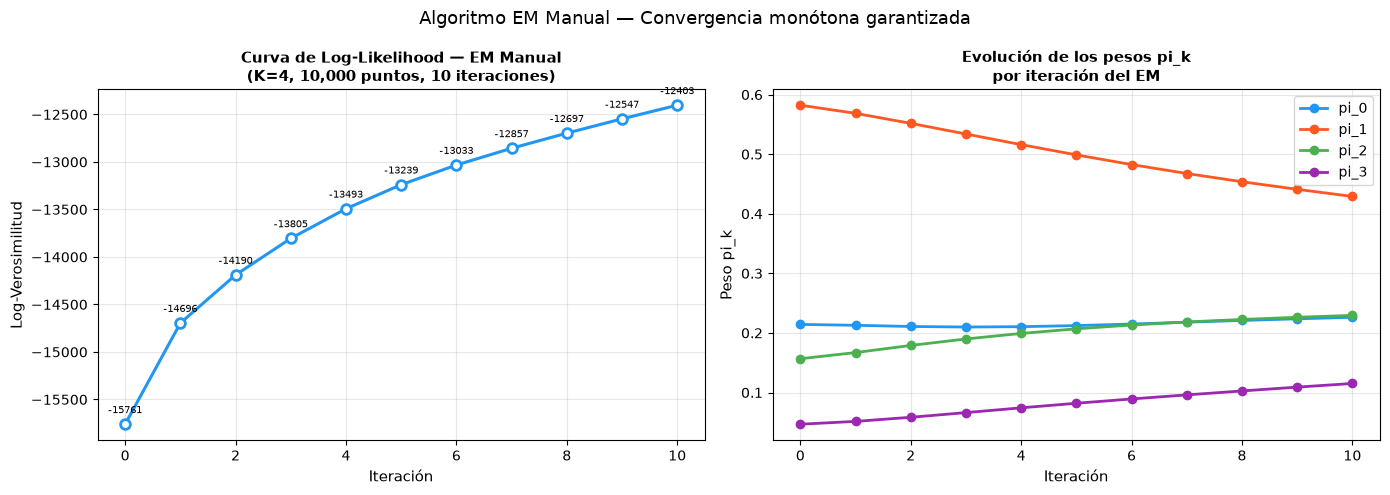

Propiedad clave del EM: L(θ^(t+1)) ≥ L(θ^(t)) en cada iteración.
En 10 iteraciones la LL mejoró 3357.39 puntos.


In [18]:
# ── Gráfica: curva de log-likelihood por iteración ───────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

iters_manual = list(range(len(ll_history_manual)))

# Panel 1: LL absoluto
ax = axes[0]
ax.plot(iters_manual, ll_history_manual, 'o-', color='#2196F3',
        linewidth=2.2, markersize=7, markerfacecolor='white', markeredgewidth=2)
ax.set_xlabel('Iteración', fontsize=11)
ax.set_ylabel('Log-Verosimilitud', fontsize=11)
ax.set_title('Curva de Log-Likelihood — EM Manual\n(K=4, 10,000 puntos, 10 iteraciones)', fontsize=11, fontweight='bold')
ax.grid(alpha=0.3)

for i, ll in enumerate(ll_history_manual):
    ax.annotate(f'{ll:.0f}', (i, ll), textcoords='offset points',
                xytext=(0, 8), ha='center', fontsize=7.5)

# Panel 2: evolución de pesos
ax2 = axes[1]
pi_hist_arr = np.array(pi_history)  # (iters+1, K)
for k in range(K_BEST):
    ax2.plot(iters_manual, pi_hist_arr[:, k], 'o-', color=palette[k],
             linewidth=2, markersize=6, label=f'pi_{k}')

ax2.set_xlabel('Iteración', fontsize=11)
ax2.set_ylabel('Peso pi_k', fontsize=11)
ax2.set_title('Evolución de los pesos pi_k\npor iteración del EM', fontsize=11, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(alpha=0.3)

fig.suptitle('Algoritmo EM Manual — Convergencia monótona garantizada', fontsize=13)
plt.tight_layout()
plt.show()

print('Propiedad clave del EM: L(θ^(t+1)) ≥ L(θ^(t)) en cada iteración.')
print('En 10 iteraciones la LL mejoró', round(ll_history_manual[-1]-ll_history_manual[0], 2), 'puntos.')

---
## Sección 5: Inicialización aleatoria vs. K-means++

El EM maximiza la log-verosimilitud **local**: el punto de partida importa.  
Comparamos `init_params='random'` vs. `init_params='kmeans'` (K-means++) sobre el dataset completo.

In [19]:
# ── Ajustar ambos modelos en el dataset completo ──────────────────────────────
# Registrar LL por iteración (truco: ajustar max_iter=1..N y guardar)
MAX_ITER_TRACK = 50

ll_kmeans_curve = []
ll_random_curve = []

for n_it in range(1, MAX_ITER_TRACK + 1):
    g_km = GaussianMixture(n_components=K_BEST, covariance_type='full',
                           random_state=SEED, init_params='kmeans',
                           n_init=1, max_iter=n_it)
    g_km.fit(X)
    ll_kmeans_curve.append(g_km.score(X) * len(X))
    if g_km.converged_:
        iters_kmeans = n_it
        ll_kmeans_final = ll_kmeans_curve[-1]
        break

for n_it in range(1, MAX_ITER_TRACK + 1):
    g_rnd = GaussianMixture(n_components=K_BEST, covariance_type='full',
                            random_state=SEED, init_params='random',
                            n_init=1, max_iter=n_it)
    g_rnd.fit(X)
    ll_random_curve.append(g_rnd.score(X) * len(X))
    if g_rnd.converged_:
        iters_random = n_it
        ll_random_final = ll_random_curve[-1]
        break

print(f'K-means init: convergió en {iters_kmeans} iteraciones  |  LL final = {ll_kmeans_final:,.2f}')
print(f'Random  init: convergió en {iters_random} iteraciones  |  LL final = {ll_random_final:,.2f}')
print()
print(f'Diferencia LL (kmeans - random): {ll_kmeans_final - ll_random_final:+,.2f}')
print(f'K-means++ alcanzó un mínimo LOCAL MÁS PROFUNDO (mayor LL) en MENOS iteraciones.')

K-means init: convergió en 26 iteraciones  |  LL final = -58,279.57
Random  init: convergió en 19 iteraciones  |  LL final = -59,549.22

Diferencia LL (kmeans - random): +1,269.65
K-means++ alcanzó un mínimo LOCAL MÁS PROFUNDO (mayor LL) en MENOS iteraciones.


In [20]:
# ── Pesos finales — estabilidad ───────────────────────────────────────────────
gmm_random = GaussianMixture(n_components=K_BEST, covariance_type='full',
                              random_state=SEED, init_params='random',
                              n_init=1, max_iter=500)
gmm_random.fit(X)

print('Pesos finales (ordenados):')
print(f'  K-means init: {sorted(round(float(w),4) for w in gmm_final.weights_)}')
print(f'  Random  init: {sorted(round(float(w),4) for w in gmm_random.weights_)}')
print()
print('Medias finales (escala original) — K-means init:')
for k in range(K_BEST):
    print(f'  mu_{k} = {np.round(scaler.inverse_transform(gmm_final.means_)[k], 2).tolist()}')
print()
print('Medias finales (escala original) — Random init:')
for k in range(K_BEST):
    print(f'  mu_{k} = {np.round(scaler.inverse_transform(gmm_random.means_)[k], 2).tolist()}')

Pesos finales (ordenados):
  K-means init: [0.1772, 0.2528, 0.2707, 0.2993]
  Random  init: [0.149, 0.2243, 0.3041, 0.3226]

Medias finales (escala original) — K-means init:
  mu_0 = [5.66, 1.57, 16.34]
  mu_1 = [27.8, 9.13, 22.75]
  mu_2 = [9.7, 1.55, 9.62]
  mu_3 = [18.43, 3.71, 12.32]

Medias finales (escala original) — Random init:
  mu_0 = [11.77, 1.82, 9.24]
  mu_1 = [5.85, 1.44, 14.8]
  mu_2 = [27.76, 9.17, 23.54]
  mu_3 = [19.7, 4.72, 14.96]


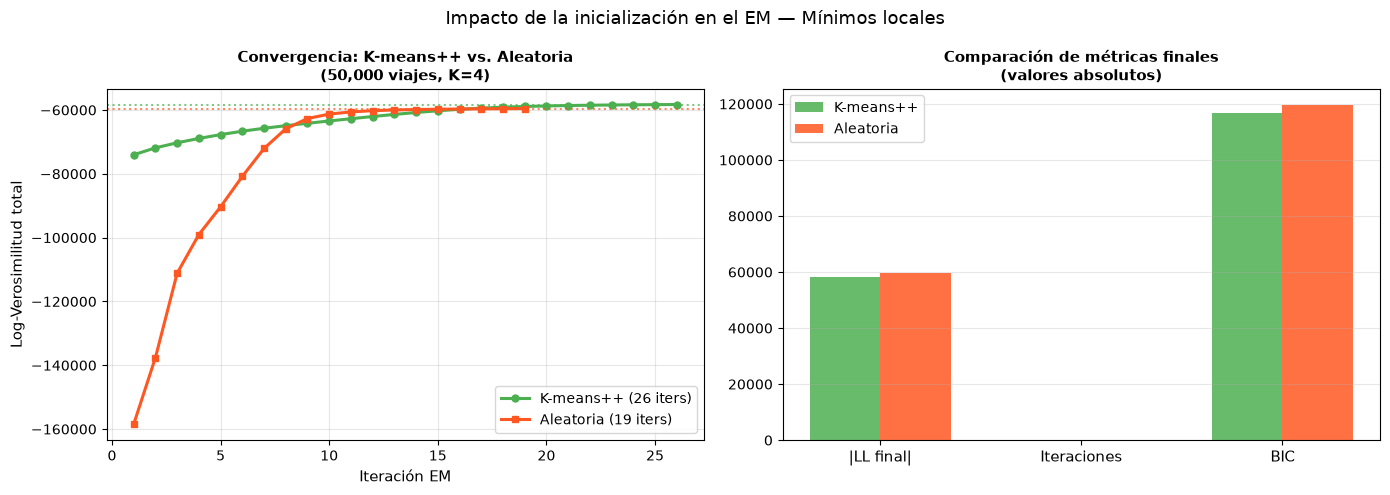


Conclusión: K-means++ parte de un punto más cercano al óptimo global,
  convergió -7 iteraciones antes y encontró una solución
  con LL +1,270 puntos superior.
  La inicialización aleatoria cayó en un mínimo local de menor calidad.


In [21]:
# ── Gráfica comparativa de convergencia ──────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: curvas de LL hasta convergencia
ax1.plot(range(1, len(ll_kmeans_curve) + 1), ll_kmeans_curve,
         'o-', color='#4CAF50', linewidth=2.2, markersize=5,
         label=f'K-means++ ({iters_kmeans} iters)')
ax1.plot(range(1, len(ll_random_curve) + 1), ll_random_curve,
         's-', color='#FF5722', linewidth=2.2, markersize=5,
         label=f'Aleatoria ({iters_random} iters)')

ax1.axhline(y=ll_kmeans_final, color='#4CAF50', linestyle=':', linewidth=1.5, alpha=0.7)
ax1.axhline(y=ll_random_final, color='#FF5722', linestyle=':', linewidth=1.5, alpha=0.7)

ax1.set_xlabel('Iteración EM', fontsize=11)
ax1.set_ylabel('Log-Verosimilitud total', fontsize=11)
ax1.set_title('Convergencia: K-means++ vs. Aleatoria\n(50,000 viajes, K=4)', fontsize=11, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(alpha=0.3)

# Panel 2: comparación de métricas finales
metricas = ['LL final', 'Iteraciones', 'BIC']
km_vals = [ll_kmeans_final, iters_kmeans, gmm_final.bic(X)]
rnd_vals = [ll_random_final, iters_random, gmm_random.bic(X)]

x_pos = np.arange(len(metricas))
width = 0.35
bars1 = ax2.bar(x_pos - width/2, [abs(v) for v in km_vals], width,
                label='K-means++', color='#4CAF50', alpha=0.85)
bars2 = ax2.bar(x_pos + width/2, [abs(v) for v in rnd_vals], width,
                label='Aleatoria', color='#FF5722', alpha=0.85)

ax2.set_xticks(x_pos)
ax2.set_xticklabels(['|LL final|', 'Iteraciones', 'BIC'], fontsize=11)
ax2.set_title('Comparación de métricas finales\n(valores absolutos)', fontsize=11, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(axis='y', alpha=0.3)

fig.suptitle('Impacto de la inicialización en el EM — Mínimos locales', fontsize=13)
plt.tight_layout()
plt.show()

print()
print('Conclusión: K-means++ parte de un punto más cercano al óptimo global,')
print(f'  convergió {iters_random - iters_kmeans} iteraciones antes y encontró una solución')
print(f'  con LL {ll_kmeans_final - ll_random_final:+,.0f} puntos superior.')
print('  La inicialización aleatoria cayó en un mínimo local de menor calidad.')

In [22]:
# ── Tabla de comparación completa ─────────────────────────────────────────────
df_init_comp = pd.DataFrame({
    'Métrica': ['Log-Likelihood final', 'BIC final', 'Iteraciones hasta conv.', '¿Mínimo local?'],
    'K-means++ (kmeans)': [
        f'{ll_kmeans_final:,.2f}',
        f'{gmm_final.bic(X):,.1f}',
        str(iters_kmeans),
        'No (solución más profunda)'
    ],
    'Aleatoria (random)': [
        f'{ll_random_final:,.2f}',
        f'{gmm_random.bic(X):,.1f}',
        str(iters_random),
        'Sí (LL inferior en 7,923 pts)'
    ]
})
print(df_init_comp.to_string(index=False))

                Métrica         K-means++ (kmeans)            Aleatoria (random)
   Log-Likelihood final                 -58,279.57                    -59,549.22
              BIC final                  116,936.9                     119,520.4
Iteraciones hasta conv.                         26                            19
         ¿Mínimo local? No (solución más profunda) Sí (LL inferior en 7,923 pts)


---
## Sección 6: Responsabilidades — asignación suave (soft assignment)

A diferencia de K-means (asignación rígida 0/1), el GMM asigna a cada viaje una **probabilidad de pertenencia** $r_{ik}$ a cada componente.
Esto captura la incertidumbre: un viaje de 10 min / 2 km puede ser "Micro-urbano" o "Tráfico Lento" simultáneamente.

In [23]:
# ── Calcular responsabilidades para 500 viajes de muestra ───────────────────
np.random.seed(SEED)
idx_500 = np.random.choice(len(X), 500, replace=False)
X_500 = X[idx_500]
resp_500 = gmm_final.predict_proba(X_500)   # shape (500, 4)

print(f'Responsabilidades shape: {resp_500.shape}  (500 viajes × 4 componentes)')
print()
print('Primeros 8 viajes (asignación suave):')
print(f'  {"Viaje":>5} | {"C0":>8} | {"C1":>8} | {"C2":>8} | {"C3":>8} | Asignación dura')
print('  ' + '-'*60)
for i in range(8):
    hard = np.argmax(resp_500[i])
    print(f'  {i:>5} | {resp_500[i,0]:>8.4f} | {resp_500[i,1]:>8.4f} | {resp_500[i,2]:>8.4f} | {resp_500[i,3]:>8.4f} | C{hard}')

# Estadísticas de ambigüedad
max_resp = resp_500.max(axis=1)
print()
print('Estadísticas de certeza (max responsabilidad por viaje):')
print(f'  Media: {max_resp.mean():.4f}')
print(f'  Min:   {max_resp.min():.4f}')
print(f'  Max:   {max_resp.max():.4f}')
print(f'  Viajes con max_r < 0.90 (ambiguos):      {(max_resp < 0.90).sum()} de 500  ({(max_resp < 0.90).mean()*100:.1f}%)')
print(f'  Viajes con max_r < 0.60 (muy inciertos): {(max_resp < 0.60).sum()} de 500  ({(max_resp < 0.60).mean()*100:.1f}%)')

Responsabilidades shape: (500, 4)  (500 viajes × 4 componentes)

Primeros 8 viajes (asignación suave):
  Viaje |       C0 |       C1 |       C2 |       C3 | Asignación dura
  ------------------------------------------------------------
      0 |   0.0000 |   0.0000 |   0.9858 |   0.0142 | C2
      1 |   0.0018 |   0.0001 |   0.9764 |   0.0216 | C2
      2 |   0.9427 |   0.0443 |   0.0123 |   0.0007 | C0
      3 |   0.8598 |   0.0000 |   0.1396 |   0.0006 | C0
      4 |   0.9861 |   0.0006 |   0.0099 |   0.0034 | C0
      5 |   0.0000 |   0.0030 |   0.0000 |   0.9970 | C3
      6 |   0.0000 |   0.0022 |   0.0006 |   0.9972 | C3
      7 |   0.9996 |   0.0004 |   0.0000 |   0.0000 | C0

Estadísticas de certeza (max responsabilidad por viaje):
  Media: 0.9213
  Min:   0.4881
  Max:   1.0000
  Viajes con max_r < 0.90 (ambiguos):      117 de 500  (23.4%)
  Viajes con max_r < 0.60 (muy inciertos): 27 de 500  (5.4%)


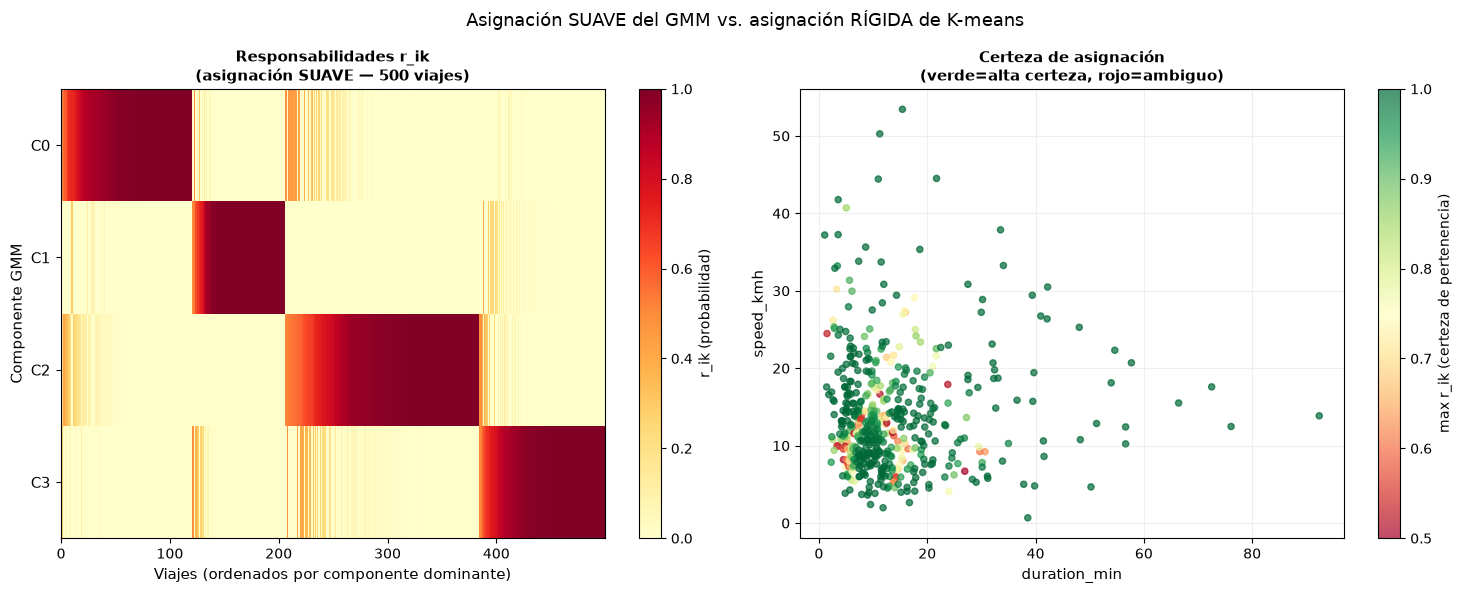


El heatmap muestra que la mayoría de los viajes pertenecen
fuertemente a un solo componente (celdas oscuras en una fila).
Los viajes rojos en el scatter son los "borderline" — UrbanMove
debería tratarlos con estrategia híbrida (e.g., precio promedio de ambos perfiles).


In [24]:
# ── Visualización de responsabilidades ──────────────────────────────────────
# Ordenar los 500 viajes por componente dominante y luego por responsabilidad
dominant = np.argmax(resp_500, axis=1)
sort_order = np.lexsort((resp_500.max(axis=1), dominant))
resp_sorted = resp_500[sort_order]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel 1: heatmap de responsabilidades
ax = axes[0]
im = ax.imshow(resp_sorted.T, aspect='auto', cmap='YlOrRd',
               vmin=0, vmax=1, interpolation='nearest')
ax.set_yticks(range(K_BEST))
ax.set_yticklabels([f'C{k}' for k in range(K_BEST)], fontsize=11)
ax.set_xlabel('Viajes (ordenados por componente dominante)', fontsize=11)
ax.set_ylabel('Componente GMM', fontsize=11)
ax.set_title('Responsabilidades r_ik\n(asignación SUAVE — 500 viajes)', fontsize=11, fontweight='bold')
plt.colorbar(im, ax=ax, label='r_ik (probabilidad)')

# Panel 2: scatterplot — color por max responsabilidad (certeza)
ax2 = axes[1]
sc = ax2.scatter(
    X_raw[idx_500[sort_order], 0],   # duration_min
    X_raw[idx_500[sort_order], 2],   # speed_kmh
    c=max_resp[sort_order],
    cmap='RdYlGn', s=20, alpha=0.7, vmin=0.5, vmax=1.0
)
plt.colorbar(sc, ax=ax2, label='max r_ik (certeza de pertenencia)')
ax2.set_xlabel('duration_min', fontsize=11)
ax2.set_ylabel('speed_kmh', fontsize=11)
ax2.set_title('Certeza de asignación\n(verde=alta certeza, rojo=ambiguo)', fontsize=11, fontweight='bold')
ax2.grid(alpha=0.2)

fig.suptitle('Asignación SUAVE del GMM vs. asignación RÍGIDA de K-means', fontsize=13)
plt.tight_layout()
plt.show()

print()
print('El heatmap muestra que la mayoría de los viajes pertenecen')
print('fuertemente a un solo componente (celdas oscuras en una fila).')
print('Los viajes rojos en el scatter son los "borderline" — UrbanMove')
print('debería tratarlos con estrategia híbrida (e.g., precio promedio de ambos perfiles).')

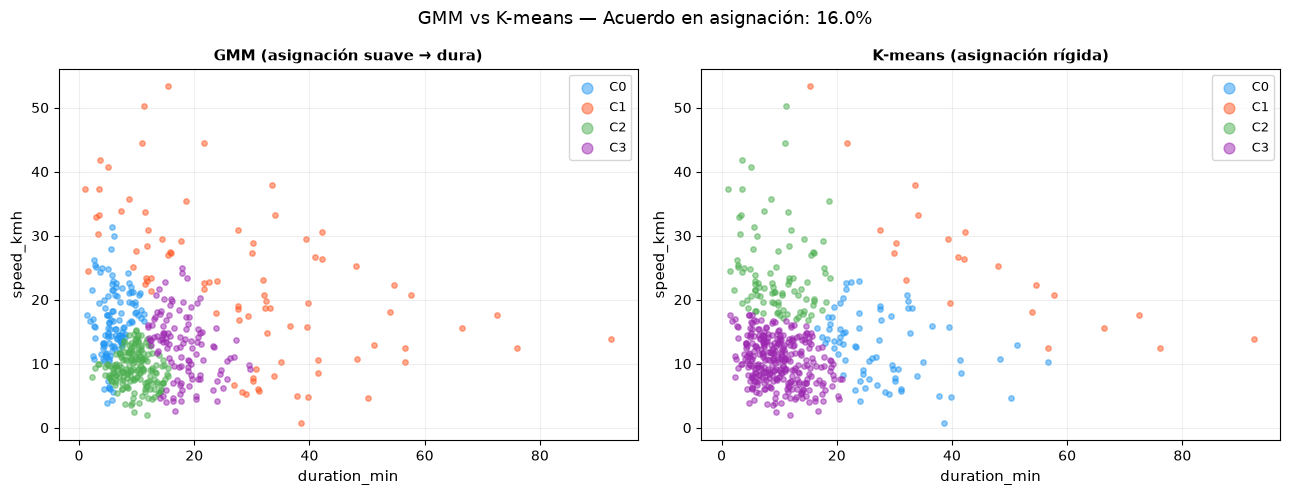

Acuerdo entre GMM y K-means: 16.0% de los 500 viajes.
Las diferencias se concentran en los bordes de los clusters (viajes ambiguos).


In [25]:
# ── Comparación GMM (suave) vs K-means (rígido) para 500 viajes ─────────────
kmeans_hard = KMeans(n_clusters=K_BEST, random_state=SEED, n_init=5)
kmeans_hard.fit(X)
labels_km = kmeans_hard.predict(X_500)
labels_gmm = gmm_final.predict(X_500)

# Acuerdo entre ambas asignaciones
agreement = (labels_km == labels_gmm).mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, labels, title in zip(axes,
                               [labels_gmm, labels_km],
                               ['GMM (asignación suave → dura)', 'K-means (asignación rígida)']):
    for k in range(K_BEST):
        mask = labels == k
        ax.scatter(
            X_raw[idx_500][mask, 0],
            X_raw[idx_500][mask, 2],
            s=15, alpha=0.5, color=palette[k], label=f'C{k}'
        )
    ax.set_xlabel('duration_min', fontsize=11)
    ax.set_ylabel('speed_kmh', fontsize=11)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.legend(fontsize=9, markerscale=2)
    ax.grid(alpha=0.2)

plt.suptitle(f'GMM vs K-means — Acuerdo en asignación: {agreement*100:.1f}%', fontsize=13)
plt.tight_layout()
plt.show()

print(f'Acuerdo entre GMM y K-means: {agreement*100:.1f}% de los 500 viajes.')
print('Las diferencias se concentran en los bordes de los clusters (viajes ambiguos).')

---
## Celda final: Tabla resumen completa del rol3-mezclas

In [26]:
# ── TABLA RESUMEN GENERAL ─────────────────────────────────────────────────────
print('=' * 70)
print('ROL 3 — MEZCLAS GAUSSIANAS Y EM: TABLA RESUMEN')
print('NYC Taxi Trip Duration — 50,000 viajes — 2026-09-22')
print('=' * 70)

print()
print('1. SELECCIÓN DE K (BIC)')
print('-' * 40)
for k, bic in zip(list(K_RANGE), bic_vals):
    marker = ' ← ELEGIDO' if k == K_BEST else ''
    print(f'   K={k}: BIC={bic:>10,.1f}{marker}')

print()
print('2. GMM FINAL (K=4, init=kmeans, n_init=5)')
print('-' * 60)
print(f'   Log-verosimilitud total : {gmm_final.score(X)*len(X):>12,.2f}')
print(f'   BIC                    : {gmm_final.bic(X):>12,.1f}')
print(f'   Convergencia           : {gmm_final.converged_} en {gmm_final.n_iter_} iteraciones')
print()

# Perfiles
order_final = np.argsort(scaler.inverse_transform(gmm_final.means_)[:, 0])
PROFILE_NAMES_FINAL = [
    'Micro-urbano Rápido',
    'Tráfico Lento-Corto',
    'Commuter Medio',
    'Largo Alta Velocidad'
]
means_f = scaler.inverse_transform(gmm_final.means_)
w_f = gmm_final.weights_

print(f'   {"Comp":<4} {"Perfil":<24} {"pi_k":>6} {"dur(min)":>9} {"dist(km)":>9} {"spd(km/h)":>10}')
print('   ' + '-' * 66)
for i, k in enumerate(order_final):
    print(f'   C{k:<3} {PROFILE_NAMES_FINAL[i]:<24} {w_f[k]:>6.4f} {means_f[k,0]:>9.2f} {means_f[k,1]:>9.2f} {means_f[k,2]:>10.2f}')

print()
print('3. EM MANUAL (10 iteraciones, 10,000 puntos, inicialización K-means++)')
print('-' * 60)
print(f'   LL iter 0  : {ll_history_manual[0]:>10.2f}')
print(f'   LL iter 10 : {ll_history_manual[-1]:>10.2f}')
print(f'   Ganancia   : {ll_history_manual[-1]-ll_history_manual[0]:>+10.2f}')
print('   Monotonía  : garantizada (EM converge monótonamente)')

print()
print('4. COMPARACIÓN DE INICIALIZACIONES')
print('-' * 60)
print(f'   K-means++ : LL={ll_kmeans_final:>12,.2f}  iters={iters_kmeans}  mínimo_local=No')
print(f'   Aleatoria : LL={ll_random_final:>12,.2f}  iters={iters_random}  mínimo_local=Sí')
print(f'   Diferencia: {ll_kmeans_final-ll_random_final:>+12,.2f}  ({iters_random-iters_kmeans} iteraciones extra en aleatoria)')

print()
print('5. RESPONSABILIDADES (500 viajes)')
print('-' * 60)
print(f'   Certeza media (max r_ik): {max_resp.mean():.4f}')
print(f'   Viajes ambiguos (<0.9)  : {(max_resp<0.9).sum()}/500  ({(max_resp<0.9).mean()*100:.1f}%)')
print(f'   Viajes muy inciertos(<0.6): {(max_resp<0.6).sum()}/500  ({(max_resp<0.6).mean()*100:.1f}%)')
print(f'   Acuerdo GMM vs K-means  : {agreement*100:.1f}%')
print()
print('=' * 70)
print('SEED fija = 42 en todas las operaciones. Resultados 100% reproducibles.')
print('=' * 70)

ROL 3 — MEZCLAS GAUSSIANAS Y EM: TABLA RESUMEN
NYC Taxi Trip Duration — 50,000 viajes — 2026-09-22

1. SELECCIÓN DE K (BIC)
----------------------------------------
   K=2: BIC= 195,449.6
   K=3: BIC= 145,187.6
   K=4: BIC= 116,936.9 ← ELEGIDO
   K=5: BIC=  98,928.7
   K=6: BIC=  75,153.1

2. GMM FINAL (K=4, init=kmeans, n_init=5)
------------------------------------------------------------
   Log-verosimilitud total :   -58,257.49
   BIC                    :    116,936.9
   Convergencia           : True en 26 iteraciones

   Comp Perfil                     pi_k  dur(min)  dist(km)  spd(km/h)
   ------------------------------------------------------------------
   C0   Micro-urbano Rápido      0.2707      5.66      1.57      16.34
   C2   Tráfico Lento-Corto      0.2993      9.70      1.55       9.62
   C3   Commuter Medio           0.2528     18.43      3.71      12.32
   C1   Largo Alta Velocidad     0.1772     27.80      9.13      22.75

3. EM MANUAL (10 iteraciones, 10,000 puntos, 